<a href="https://colab.research.google.com/github/VilasiniRamamoorthy/Mini_Project1/blob/main/visualizations.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

**Data Visualization**

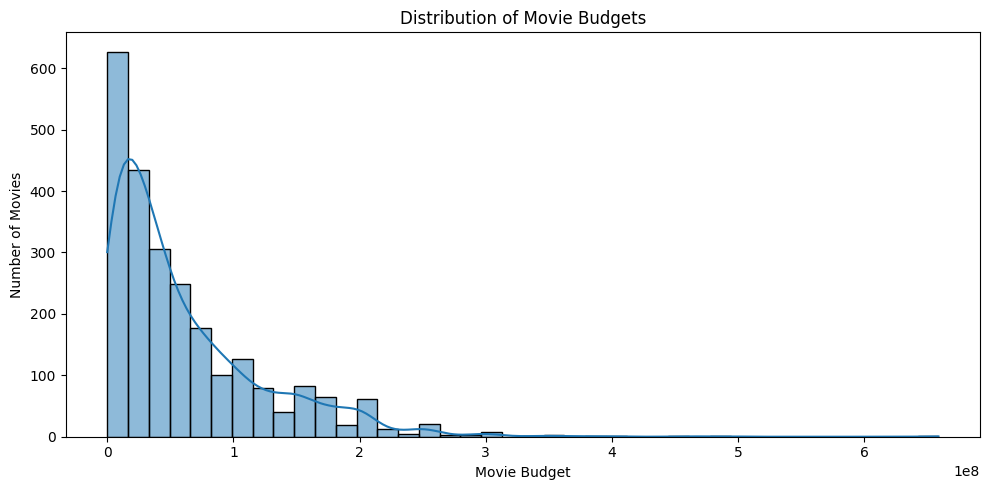

Mean budget: 60821433.92
Median budget: 40000000.0
Skewness: 1.95
Insight: Movie budgets are strongly right-skewed. Most movies have comparatively lower budgets, while a small number of high-budget movies pull the mean upward.


In [ ]:
#Data Visualization
#Univariate
#(i) Distribution of movie budgets (histogram/KDE).
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# Load the dataset
df = pd.read_csv("movies.csv")

# Remove missing and zero budgets for this analysis
budget_data = df.loc[df["budget"].notna() & (df["budget"] > 0), "budget"]

# Create histogram and KDE curve
plt.figure(figsize=(10, 5))

sns.histplot(budget_data, bins=40, kde=True)

plt.title("Distribution of Movie Budgets")
plt.xlabel("Movie Budget")
plt.ylabel("Number of Movies")
plt.tight_layout()
plt.show()

# Calculate statistics to support the insight
print("Mean budget:", round(budget_data.mean(), 2))
print("Median budget:", round(budget_data.median(), 2))
print("Skewness:", round(budget_data.skew(), 2))

# Generate an insight
if budget_data.skew() > 1:
    print("Insight: Movie budgets are strongly right-skewed. Most movies "
          "have comparatively lower budgets, while a small number of "
          "high-budget movies pull the mean upward.")
elif budget_data.skew() > 0:
    print("Insight: Movie budgets are moderately right-skewed, suggesting "
          "that some high-budget movies raise the average.")
else:
    print("Insight: Movie budgets are not strongly right-skewed. Compare "
          "the mean and median to understand the distribution.")


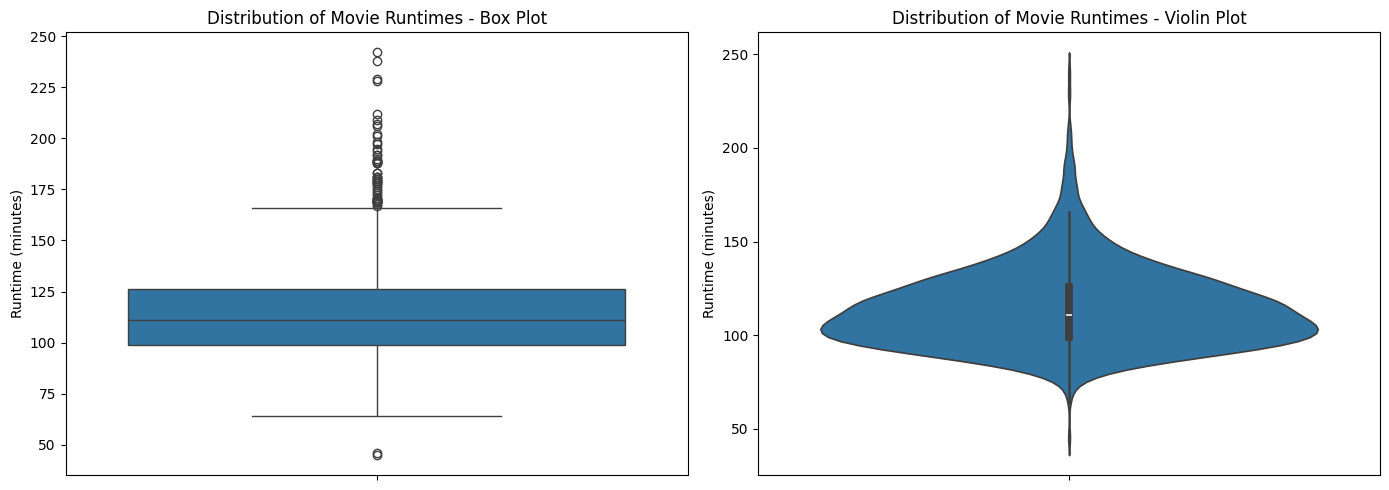

Valid runtime count: 2509
Mean runtime: 114.42 minutes
Median runtime: 111.0 minutes
Minimum runtime: 45 minutes
Maximum runtime: 242 minutes
25th percentile: 99.0
75th percentile: 126.0


In [ ]:
#Data Visualization
#Univariate
#(ii) Distribution of runtimes (box plot / violin plot).
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# Load the dataset
df = pd.read_csv("movies.csv")

# Select valid runtime values
runtime_data = df.loc[df["runtime"].notna() & (df["runtime"] > 0), "runtime"]

# Create box plot and violin plot
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Box plot
sns.boxplot(y=runtime_data, ax=axes[0])
axes[0].set_title("Distribution of Movie Runtimes - Box Plot")
axes[0].set_ylabel("Runtime (minutes)")

# Violin plot
sns.violinplot(y=runtime_data, ax=axes[1])
axes[1].set_title("Distribution of Movie Runtimes - Violin Plot")
axes[1].set_ylabel("Runtime (minutes)")

plt.tight_layout()
plt.show()

# Summary statistics
print("Valid runtime count:", runtime_data.count())
print("Mean runtime:", round(runtime_data.mean(), 2), "minutes")
print("Median runtime:", round(runtime_data.median(), 2), "minutes")
print("Minimum runtime:", runtime_data.min(), "minutes")
print("Maximum runtime:", runtime_data.max(), "minutes")
print("25th percentile:", runtime_data.quantile(0.25))
print("75th percentile:", runtime_data.quantile(0.75))


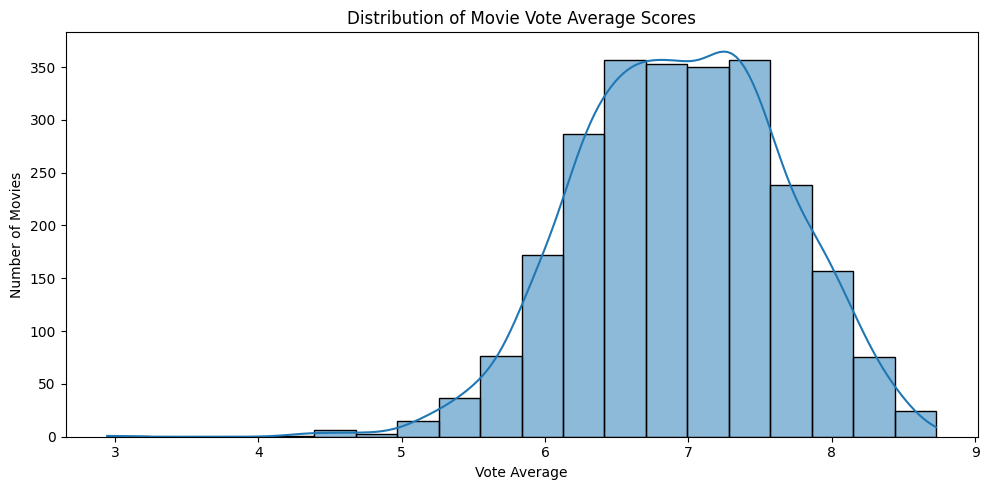

In [ ]:
#Data Visualization
#Univariate
#(iii) Distribution of vote_average scores (histogram).
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# Load the dataset
df = pd.read_csv("movies.csv")

# Remove missing values and keep valid ratings
vote_data = df.loc[df["vote_average"].notna(),"vote_average"]

# Create histogram
plt.figure(figsize=(10, 5))

sns.histplot(
    vote_data,
    bins=20,
    kde=True
)

plt.title("Distribution of Movie Vote Average Scores")
plt.xlabel("Vote Average")
plt.ylabel("Number of Movies")
plt.tight_layout()
plt.show()

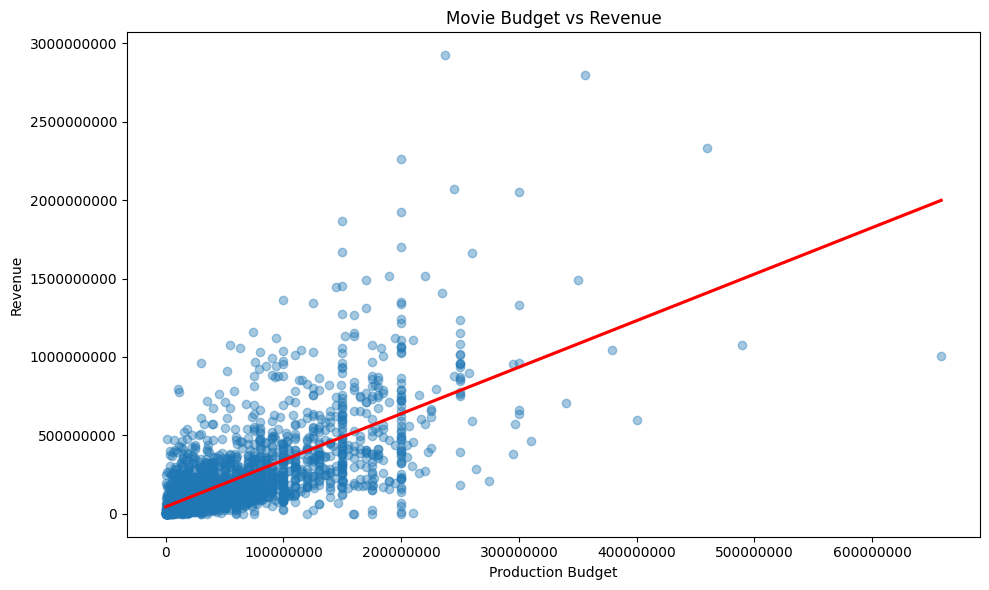

In [ ]:
#Data Visualization
#Bivariate - Budget vs revenue (scatter plot, with trend line).
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# Load the dataset
df = pd.read_csv("movies.csv")

# Select valid budget and revenue values
budget_revenue = df.loc[ df["budget"].notna() & df["revenue"].notna() & (df["budget"] > 0) & (df["revenue"] > 0),
    ["budget", "revenue"]]

# Create scatter plot with trend line
plt.figure(figsize=(10, 6))

sns.regplot(
    data=budget_revenue,
    x="budget",
    y="revenue",
    scatter_kws={"alpha": 0.4},
    line_kws={"color": "red"},
    ci=None
)

plt.title("Movie Budget vs Revenue")
plt.xlabel("Production Budget")
plt.ylabel("Revenue")
plt.ticklabel_format(style="plain", axis="both")
plt.tight_layout()
plt.show()

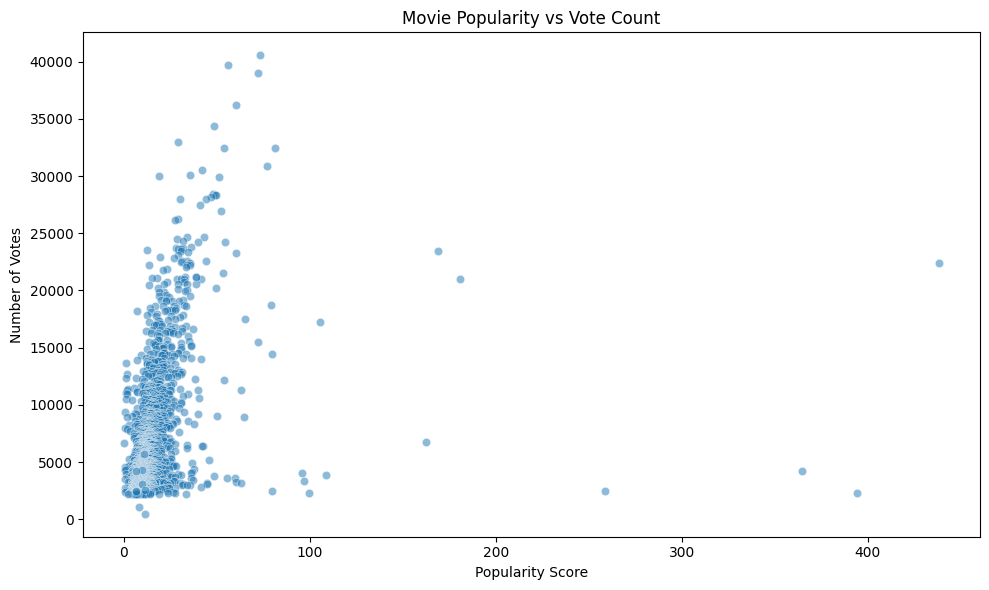

In [ ]:
#Data Visualization
#Bivariate - Popularity vs vote count (scatter plot).
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# Load the dataset
df = pd.read_csv("movies.csv")

# Select valid popularity and vote_count values
pop_vote = df.loc[
    df["popularity"].notna() &
    df["vote_count"].notna() &
    (df["popularity"] >= 0) &
    (df["vote_count"] >= 0),
    ["popularity", "vote_count"]
]

# Create scatter plot
plt.figure(figsize=(10, 6))

sns.scatterplot(
    data=pop_vote,
    x="popularity",
    y="vote_count",
    alpha=0.5
)

plt.title("Movie Popularity vs Vote Count")
plt.xlabel("Popularity Score")
plt.ylabel("Number of Votes")
plt.tight_layout()
plt.show()

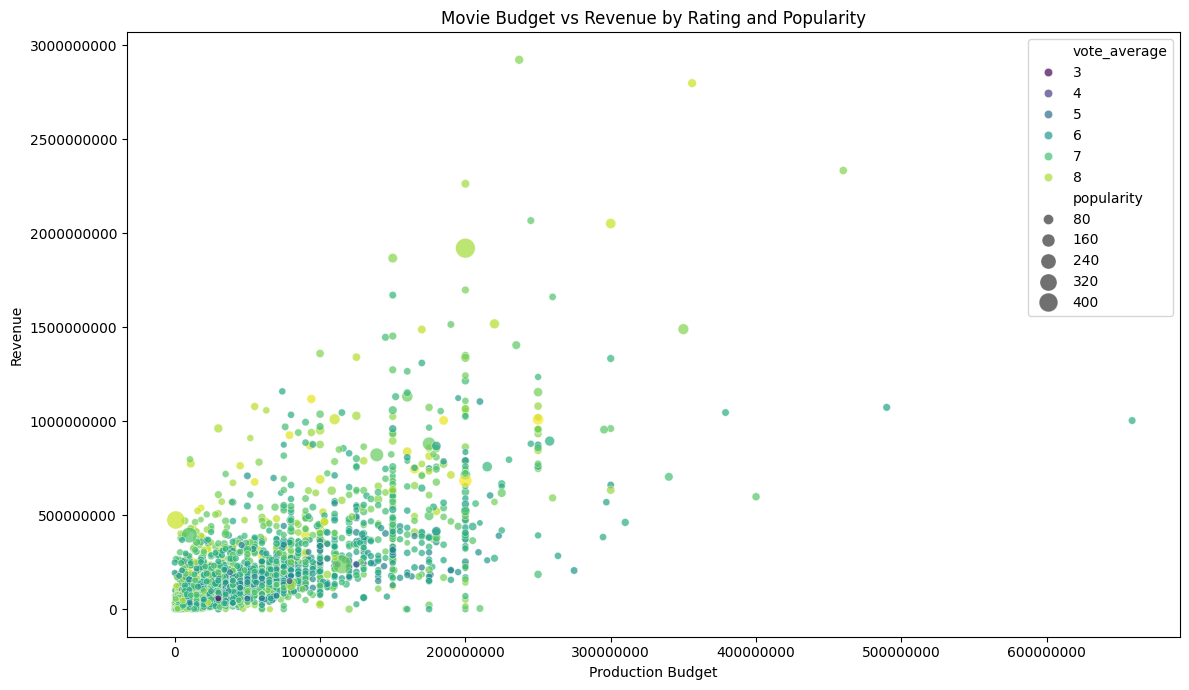

In [ ]:
#Data Visualization
#Multi - Correlation heatmap of budget, revenue, runtime, popularity, vote_average and vote_count (heatmap).
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# Load the dataset
df = pd.read_csv("movies.csv")

# Select required columns and remove missing values
movie_data = df[
    ["budget", "revenue", "popularity", "vote_average"]
].dropna()

# Keep valid budget and revenue values
movie_data = movie_data[
    (movie_data["budget"] > 0) &
    (movie_data["revenue"] > 0) &
    (movie_data["popularity"] >= 0)
]

plt.figure(figsize=(12, 7))

sns.scatterplot(
    data=movie_data,
    x="budget",
    y="revenue",
    hue="vote_average",
    size="popularity",
    sizes=(20, 200),
    palette="viridis",
    alpha=0.7
)

plt.title("Movie Budget vs Revenue by Rating and Popularity")
plt.xlabel("Production Budget")
plt.ylabel("Revenue")
plt.ticklabel_format(style="plain", axis="both")
plt.tight_layout()
plt.show()

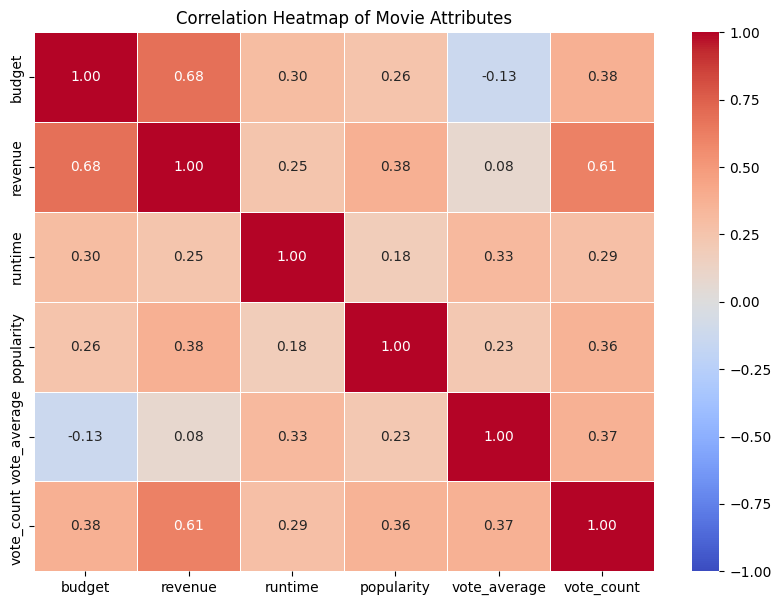

In [12]:
#Multi - Correlation heatmap of budget, revenue, runtime, popularity, vote_average and vote_count (heatmap).
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# Read CSV file
df = pd.read_csv("movies.csv")

# Select required numerical columns
cols = [
    "budget",
    "revenue",
    "runtime",
    "popularity",
    "vote_average",
    "vote_count"
]

# Create a copy of selected columns
corr_data = df[cols].copy()

# Remove missing values
corr_data = corr_data.dropna()

# Calculate correlation
correlation = corr_data.corr()

# Plot heatmap
plt.figure(figsize=(10, 7))

sns.heatmap(
    correlation,
    annot=True,
    cmap="coolwarm",
    fmt=".2f",
    linewidths=0.5,
    vmin=-1,
    vmax=1
)

plt.title("Correlation Heatmap of Movie Attributes")
plt.show()

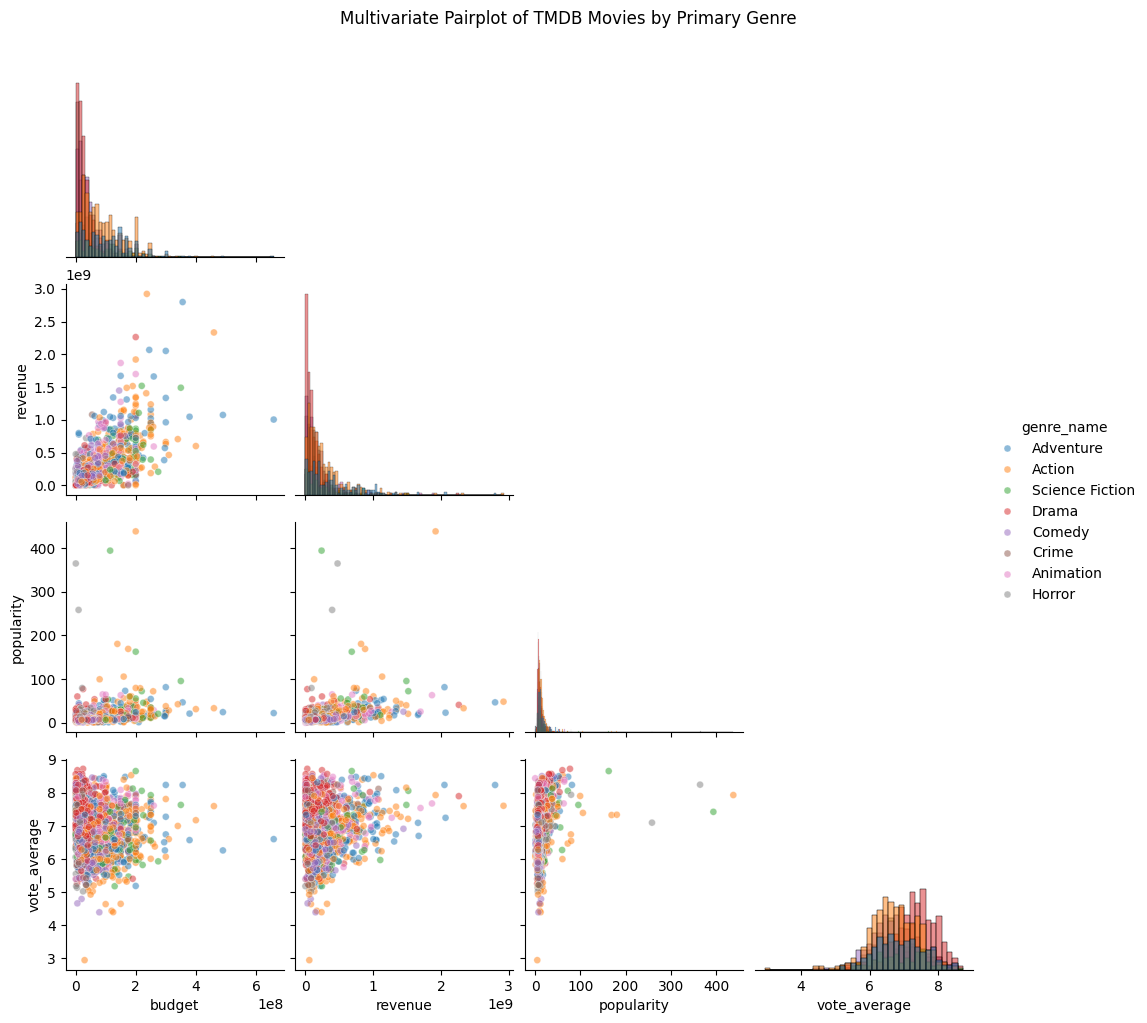

In [13]:
#Multi - Pairplot of budget, revenue, popularity and vote_average, colored by primary genre (pairplot)
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt

# Read CSV files
movies = pd.read_csv("movies.csv")
movie_genres = pd.read_csv("movie_genres.csv")
genres = pd.read_csv("genres.csv")

# Merge movies with movie_genres
df = pd.merge(
    movies,
    movie_genres,
    on="movie_id",
    how="left"
)

# Merge with genre master
df = pd.merge(
    df,
    genres,
    on="genre_id",
    how="left"
)

# Select primary genre (first genre for each movie)
df = df.drop_duplicates(subset=["movie_id"])

# Select required columns
pair_data = df[
    ["budget", "revenue", "popularity", "vote_average", "genre_name"]
].copy()

# Remove missing values
pair_data = pair_data.dropna()

# Remove invalid budget and revenue values
pair_data = pair_data[
    (pair_data["budget"] > 0) &
    (pair_data["revenue"] > 0)
]

# Limit to top 8 genres for better visualization
top_genres = pair_data["genre_name"].value_counts().head(8).index

pair_data = pair_data[
    pair_data["genre_name"].isin(top_genres)
]

# Create pairplot
sns.pairplot(
    pair_data,
    vars=["budget", "revenue", "popularity", "vote_average"],
    hue="genre_name",
    diag_kind="hist",
    corner=True,
    plot_kws={"alpha": 0.5, "s": 25}
)

plt.suptitle(
    "Multivariate Pairplot of TMDB Movies by Primary Genre",
    y=1.02
)

plt.show()

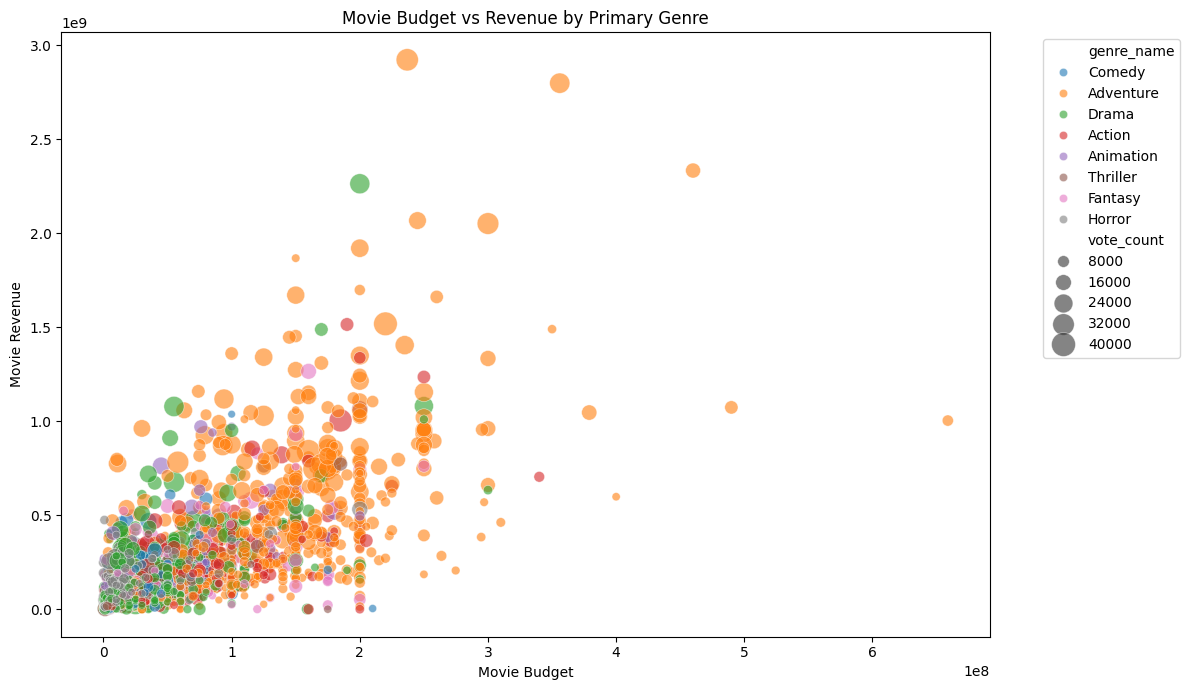

In [14]:
#Multi - Budget vs revenue colored by primary genre, with point size showing vote_count (scatter plot with hue and size)
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt

# Read CSV files
movies = pd.read_csv("movies.csv")
movie_genres = pd.read_csv("movie_genres.csv")
genres = pd.read_csv("genres.csv")

# Merge movies with movie_genres
df = pd.merge(
    movies,
    movie_genres,
    on="movie_id",
    how="left"
)

# Merge with genre master
df = pd.merge(
    df,
    genres,
    on="genre_id",
    how="left"
)

# Sort genre mapping to select first genre per movie
df = df.sort_values(["movie_id", "genre_id"])

# Select one primary genre per movie
df = df.drop_duplicates(subset=["movie_id"], keep="first")

# Select required columns
plot_data = df[
    ["title", "budget", "revenue", "vote_count", "genre_name"]
].copy()

# Remove missing values
plot_data = plot_data.dropna()

# Remove zero or invalid values
plot_data = plot_data[
    (plot_data["budget"] > 0) &
    (plot_data["revenue"] > 0) &
    (plot_data["vote_count"] > 0)
]

# Select top 8 genres
top_genres = plot_data["genre_name"].value_counts().head(8).index

plot_data = plot_data[
    plot_data["genre_name"].isin(top_genres)
]

# Create scatter plot
plt.figure(figsize=(12, 7))

sns.scatterplot(
    data=plot_data,
    x="budget",
    y="revenue",
    hue="genre_name",
    size="vote_count",
    sizes=(30, 300),
    alpha=0.6
)

plt.title("Movie Budget vs Revenue by Primary Genre")
plt.xlabel("Movie Budget")
plt.ylabel("Movie Revenue")

plt.legend(
    bbox_to_anchor=(1.05, 1),
    loc="upper left"
)

plt.tight_layout()
plt.show()

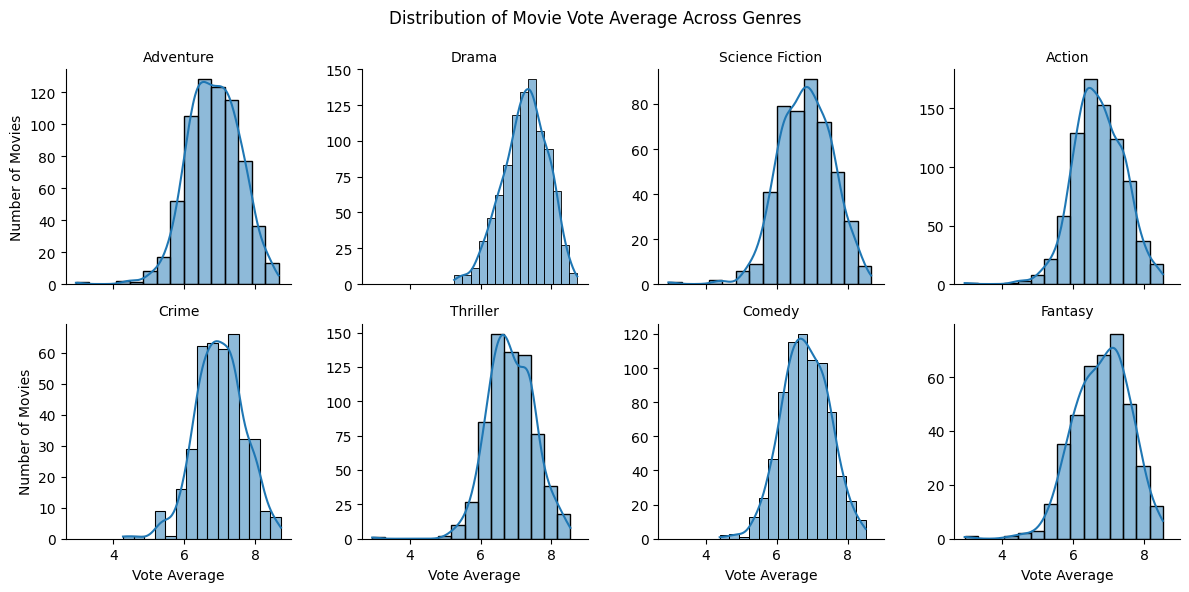

In [15]:
#Multi - Distribution of vote_average for each genre in separate panels (FacetGrid with histograms)
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt

# Read CSV files
movies = pd.read_csv("movies.csv")
movie_genres = pd.read_csv("movie_genres.csv")
genres = pd.read_csv("genres.csv")

# Merge the datasets
df = pd.merge(movies, movie_genres, on="movie_id", how="inner")
df = pd.merge(df, genres, on="genre_id", how="inner")

# Select required columns
plot_data = df[["title", "vote_average", "genre_name"]].copy()

# Remove missing values
plot_data = plot_data.dropna()

# Keep valid vote averages
plot_data = plot_data[
    (plot_data["vote_average"] >= 0) &
    (plot_data["vote_average"] <= 10)
]

# Select top 8 genres based on movie count
top_genres = plot_data["genre_name"].value_counts().head(8).index

plot_data = plot_data[
    plot_data["genre_name"].isin(top_genres)
]

# Create FacetGrid
g = sns.FacetGrid(
    plot_data,
    col="genre_name",
    col_wrap=4,
    height=3,
    sharex=True,
    sharey=False
)

# Add histogram to each panel
g.map_dataframe(
    sns.histplot,
    x="vote_average",
    bins=15,
    kde=True
)

# Add titles and labels
g.set_axis_labels("Vote Average", "Number of Movies")
g.set_titles("{col_name}")

plt.subplots_adjust(top=0.88)
g.fig.suptitle("Distribution of Movie Vote Average Across Genres")

plt.show()

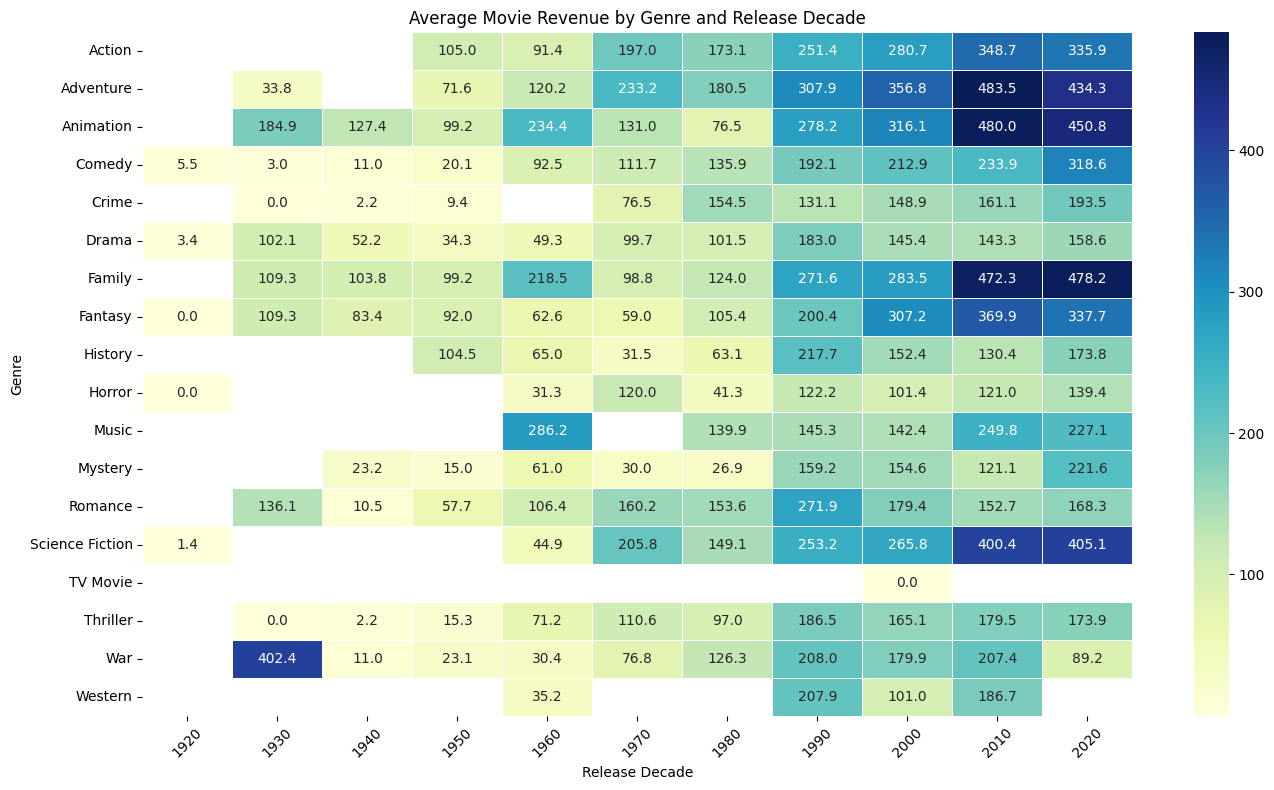

In [16]:
#Multi - •	Average revenue by genre and release decade (heatmap of a pivot table)
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt

# Read CSV files
movies = pd.read_csv("movies.csv")
movie_genres = pd.read_csv("movie_genres.csv")
genres = pd.read_csv("genres.csv")

# Merge datasets
df = pd.merge(movies, movie_genres, on="movie_id", how="inner")
df = pd.merge(df, genres, on="genre_id", how="inner")

# Convert release date into datetime
df["release_date"] = pd.to_datetime(df["release_date"], errors="coerce")

# Extract release year
df["release_year"] = df["release_date"].dt.year

# Create release decade
df["release_decade"] = (df["release_year"] // 10) * 10

# Select required columns
plot_data = df[
    ["genre_name", "release_decade", "revenue"]
].copy()

# Remove missing and invalid values
plot_data = plot_data.dropna()

plot_data = plot_data[
    (plot_data["revenue"] > 0) &
    (plot_data["release_decade"] >= 1900)
]

# Calculate average revenue using pivot table
pivot_data = plot_data.pivot_table(
    index="genre_name",
    columns="release_decade",
    values="revenue",
    aggfunc="mean"
)

# Create heatmap
plt.figure(figsize=(14, 8))

sns.heatmap(
    pivot_data / 1_000_000,
    annot=True,
    fmt=".1f",
    cmap="YlGnBu",
    linewidths=0.5
)

plt.title("Average Movie Revenue by Genre and Release Decade")
plt.xlabel("Release Decade")
plt.ylabel("Genre")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()